# CA1 - Data Visualisation and Communication 

<a id="1"></a>
## Cover Page

Lecturer Name: Taufique Ahmed 
### Barbara Souza 2023059
### GitHub Link
https://github.com/BarbSouza/data-visualisation.git
### Video Link
https://drive.google.com/drive/folders/19yAy5wb7vKj4OV-kTpZ81bX17kZqhXc9?usp=drive_link 

<a id="0"></a>
## Table of Contents
1. [Cover Page](#1)
2. [Introduction](#2)
3. [Imports](#3)
4. [Loading dataset and field descriptions](#4)
    1. [Field descriptions](#5)
5. [Dataset info and understanding it](#6)
6. [Cleaning](#7)
7. [Selecting the rows](#8)
8. [Visualisations](#9)
   1. [Visualisation 1 - Bar Chart](#10)
   2. [Visualisation 2 - Histogram](#11)
   3. [Visualisation 3 - Scatter Plot](#12)
   4. [Visualisation 4 - Pie Chart](#13)
   5. [Visualisation 5 - Heatmap](#14)
9. [Challenge](#15)
   1. [Loading dataset for year](#16)
      1. [2021](#17)
      2. [2022](#18)
      3. [2024](#19)
      4. [2025](#20)
      5. [Combining tables](#21)
   3. [Visualisation 6 - Line Chart](#22)
   4. [Visualisation 7 - Line Chart](#23)
   5. [Visualisation 8 - Grouped Bar Chart](#24)
10. [References](#25)

<a id="2"></a>
## Introduction

This notebook will show the creation of 8 visualisations into employment in fields involving **AI, Data Science and Software Development** and the insights collected from it.

The first 5 visualisations are built on **May 2023 Occupational Employement and wage Statistics (OEWS)** from the U.S. Bureau of Labor Statistics (https://www.bls.gov/oes/tables.htm). The data is organized with each row as one occupation in one area (U.S., state, metropolitan area) and one industry, with wage information and the employees number.

The structure of the notebook:
1. Loading and exploring the dataset
2. Cleaning of the data
3. Visualisations 1 to 5 (2023 dataset): Objective, type of chart and the learning outcomes
4. Visualisations 6 to 8 (2021, 2022, 2023, 2024, 2025 datasets): Objective, type of chart and the learning outcomes of the trends over the time
5. References

The code in this notebook is based on the class notebooks provided by the lecturer (Ahmed, n.d.).

**Fields**
For this analysis of data it was taken the  **Computer and Mathematical Occupations** group for having AI, Data Science and Software Development work inside. The occupation codes (`OCC_CODE`) that starts with **15-**.


Occupations compared in visualisation 4 to 8:
| Code | Occupation | Why |
|---|---|---|
| 15-1221 | Computer and Information Reaserch Scientists | Occupation closest to AI for researchs on new computing technology |
| 15-2051 | Data Scientists | Occupation closest to machine learning work such as build models to analyse data |
| 15-1252 | Software Developers | Build the software that use AI |
| 15-1253 | Software Quality Assurance Analysts and Testers | Test the software |
| 15-1251 | Computer Programmers | Writes and tests the code |

<a id="3"></a>
## Imports

In [124]:
import pandas as pd
import numpy as np
import plotly.express as px

<a id="4"></a>
## Loading dataset and field descriptions

In [59]:
dataset =  pd.read_excel("all_data_M_2023.xlsx")

<a id="5"></a>
### Field Descriptions
The file contains a second sheet ("Field Descriptions") explaining each column. 
The used **Columns** for the visualisations:
| Field | Description |
|---|---|
| AREA_TITLE | Area name |
| AREA_TYPE | Area type: 1= U.S.; 2= State; 3= U.S. Territory; 4= Metropolitan Statistical Area (MSA) or New England City and Town Area (NECTA); 6= Nonmetropolitan Area |
| NAICS_TITLE | North American Industry Classification System (NAICS) title for the given industry |
| I_GROUP | Industry level. Indicates cross-industry or NAICS sector, 3-digit, 4-digit, 5-digit, or 6-digit industry |
| OCC_CODE | The 6-digit Standard Occupational Classification (SOC) code or OEWS-specific code for the occupation |
| OCC_TITLE | SOC title or OEWS-specific title for the occupation |
| O_GROUP | Occupation level: total, major, minor, broad or detailed |
| TOT_EMP | Estimated total employment rounded to the nearest 10 (excludes self-employed) |
| A_MEAN | Annual wage |
| A_MEDIAN | Annual wage median percentile |

**Symbols used in the data:**
- `*` = indicates that a wage estimate is not available
- `**` = indicates that an employment estimate is not available
- `#` = indicates a wage equal to or greater than `$115.00` per hour or `$239,200` per year 
- `~` = indicates that the percent of establishments reporting the occupation is less than 0.5%

<a id="6"></a>
## Dataset info and understanding it

In [125]:
#Show the first 10 rows
dataset.head(10)

,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN
3,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1010,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN
4,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1011,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN
5,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1020,General and Operations Managers,...,48.69,77.06,111.59,46340,65180,101280,160290,232110,NaN,NaN
6,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1021,General and Operations Managers,...,48.69,77.06,111.59,46340,65180,101280,160290,232110,NaN,NaN
7,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1030,Legislators,...,*,*,*,21010,28810,47290,82200,129510,True,NaN
8,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1031,Legislators,...,*,*,*,21010,28810,47290,82200,129510,True,NaN
9,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-2000,"Advertising, Marketing, Promotions, Public Relations, and Sales Managers",...,67.23,96.15,#,69170,99180,139850,199990,#,NaN,NaN


In [126]:
# Number of rows and columns
dataset.shape

(413327, 32)

In [127]:
# Column names, data types and non-empty values
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 413327 entries, 0 to 413326
Data columns (total 32 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   AREA          413327 non-null  int64 
 1   AREA_TITLE    413327 non-null  object
 2   AREA_TYPE     413327 non-null  int64 
 3   PRIM_STATE    413327 non-null  object
 4   NAICS         413327 non-null  object
 5   NAICS_TITLE   413327 non-null  object
 6   I_GROUP       413327 non-null  object
 7   OWN_CODE      413327 non-null  int64 
 8   OCC_CODE      413327 non-null  object
 9   OCC_TITLE     413327 non-null  object
 10  O_GROUP       413327 non-null  object
 11  TOT_EMP       413327 non-null  object
 12  EMP_PRSE      413327 non-null  object
 13  JOBS_1000     235826 non-null  object
 14  LOC_QUOTIENT  235826 non-null  object
 15  PCT_TOTAL     170470 non-null  object
 16  PCT_RPT       170470 non-null  object
 17  H_MEAN        413327 non-null  object
 18  A_MEAN        413327 non

Only AREA, AREA_TYPE and OWN_CODE are numeric
That should be fixed so in the charts all information can be counted and visualised, the reason they are text is because a few cells contain symbols because of the missing data.

In [128]:
# Count empty cells in each column
dataset.isnull().sum()

AREA                 0
AREA_TITLE           0
AREA_TYPE            0
PRIM_STATE           0
NAICS                0
NAICS_TITLE          0
I_GROUP              0
OWN_CODE             0
OCC_CODE             0
OCC_TITLE            0
O_GROUP              0
TOT_EMP              0
EMP_PRSE             0
JOBS_1000       177501
LOC_QUOTIENT    177501
PCT_TOTAL       242857
PCT_RPT         242857
H_MEAN               0
A_MEAN               0
MEAN_PRSE            0
H_PCT10              0
H_PCT25              0
H_MEDIAN             0
H_PCT75              0
H_PCT90              0
A_PCT10              0
A_PCT25              0
A_MEDIAN             0
A_PCT75              0
A_PCT90              0
ANNUAL          396830
HOURLY          412572
dtype: int64

Jobs_1000 and LOC_QUOITIENT exists only for state and metropolitan area rows
pct_TOTAL and PCT_RPT are empty because they only exist for national industry rows
ANNUAL and Hourly are almost entirely empty becaus they are only filled for unusual occupations.

In [129]:
#Statistics of the numeric columns
dataset.describe()

,AREA,AREA_TYPE,OWN_CODE
count,4.133270e+05,413327.000000,413327.000000
mean,3.784693e+05,2.766826,717.279984
std,1.135906e+06,1.780825,601.852382
min,1.000000e+00,1.000000,1.000000
25%,9.900000e+01,1.000000,5.000000
50%,9.900000e+01,2.000000,1235.000000
75%,3.710000e+04,4.000000,1235.000000
max,7.800001e+06,6.000000,1235.000000


Only shows the code columns so the avarages are not meaninful

In [130]:
# Number of rows for each area type
dataset.value_counts("AREA_TYPE")

AREA_TYPE
1    177501
4    149591
6     48559
2     36643
3      1033
Name: count, dtype: int64

rows per kind of area
- 1 - Whole US
- 2 - states
- 3 - territories
- 4 - metropolitan
- 6 - non-metropolitan

In [131]:
# Number of rows for each industry level
dataset.value_counts("I_GROUP")

I_GROUP
cross-industry               237229
4-digit                       83350
3-digit                       39097
sector                        16376
5-digit                       15518
4-digit, ownership             9856
cross-industry, ownership      5628
3-digit, ownership             4561
6-digit                        1712
Name: count, dtype: int64

In [132]:
# Number of rows for each occupation level
dataset.value_counts("O_GROUP")

O_GROUP
detailed    306185
broad        62131
minor        23374
major        20601
total         1036
Name: count, dtype: int64

In [133]:
# Numbers of rows for each ownership type
dataset.value_counts("OWN_CODE")

OWN_CODE
1235    237229
5       144246
235       8465
2         6419
3         6076
57        3689
123       3538
1         1878
58         960
59         827
Name: count, dtype: int64

In [134]:
# How often each employment value appears
# ** missing data
dataset.value_counts("TOT_EMP")

TOT_EMP
40           19325
50           16872
60           14450
70           12537
**           11598
             ...  
151853870        1
130039030        1
22068580         1
21814850         1
18533450         1
Name: count, Length: 12271, dtype: int64

In [135]:
# How often each median wage value appears
# * missing data, # wage equal to or greater than `$115.00` per hour or `$239,200` per year 
dataset.value_counts("A_MEDIAN")

A_MEDIAN
*         5083
#         2391
41600      618
31200      584
52000      572
          ... 
237780       1
236650       1
236920       1
238120       1
238160       1
Name: count, Length: 16664, dtype: int64

Need to seperate the rows so the same ocuppation don't get count more than once

**What I learned:** The wage and employment wage are text because of the symbols, so I need to convert to numbers before the visualisations are created. The same ossupation appears many times, because of showing up once per area, per industry and per occupation level, so the rows need filtering to one leval each before adding or comparing numbers in charts.

<a id="7"></a>
## Cleaning

In [136]:
# Creating a copy to not change the original
clean = dataset.copy()

For each employment and wage column used, `#` is replaced with the lowest value it can mean (`$239,200`) and pd.to_numeric(errors="coerce") turns the column into numbers, so `*` and `**` is NaN (missing values)

In [137]:
#Columns I will use in the charts
for col in ["A_MEDIAN", "TOT_EMP", "A_MEAN"]:
    clean[col] = clean[col].replace("#", 239200)
    clean[col] = pd.to_numeric(clean[col], errors="coerce")

In [138]:
# Check the columns are now numeric
clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 413327 entries, 0 to 413326
Data columns (total 32 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   AREA          413327 non-null  int64  
 1   AREA_TITLE    413327 non-null  object 
 2   AREA_TYPE     413327 non-null  int64  
 3   PRIM_STATE    413327 non-null  object 
 4   NAICS         413327 non-null  object 
 5   NAICS_TITLE   413327 non-null  object 
 6   I_GROUP       413327 non-null  object 
 7   OWN_CODE      413327 non-null  int64  
 8   OCC_CODE      413327 non-null  object 
 9   OCC_TITLE     413327 non-null  object 
 10  O_GROUP       413327 non-null  object 
 11  TOT_EMP       401729 non-null  float64
 12  EMP_PRSE      413327 non-null  object 
 13  JOBS_1000     235826 non-null  object 
 14  LOC_QUOTIENT  235826 non-null  object 
 15  PCT_TOTAL     170470 non-null  object 
 16  PCT_RPT       170470 non-null  object 
 17  H_MEAN        413327 non-null  object 
 18  A_ME

In [139]:
#Rows with no employment number
clean["TOT_EMP"].isnull().sum()

np.int64(11598)

In [140]:
#Rows with no median wage
clean["A_MEDIAN"].isnull().sum()

np.int64(5083)

In [141]:
#Statistics now include employment and wages
clean.describe()

,AREA,AREA_TYPE,OWN_CODE,TOT_EMP,A_MEAN,A_MEDIAN
count,4.133270e+05,413327.000000,413327.000000,4.017290e+05,4.082440e+05,408244.000000
mean,3.784693e+05,2.766826,717.279984,1.275895e+04,6.810923e+04,63460.996610
std,1.135906e+06,1.780825,601.852382,3.608032e+05,3.866052e+04,33782.605405
min,1.000000e+00,1.000000,1.000000,3.000000e+01,1.675000e+04,15080.000000
25%,9.900000e+01,1.000000,5.000000,1.000000e+02,4.321000e+04,40160.000000
50%,9.900000e+01,2.000000,1235.000000,3.200000e+02,5.734000e+04,53430.000000
75%,3.710000e+04,4.000000,1235.000000,1.530000e+03,8.143000e+04,76970.000000
max,7.800001e+06,6.000000,1235.000000,1.518539e+08,1.805790e+06,239200.000000


<a id="8"></a>
## Selecting Rows for the visualisations

Creating tables with detailed occupations
| Table | Filter | Used in Visualisation |
|---|---|---|
| national | `AREA_TYPE 1` (Whole U.S.), `cross-industry` (all industries) | 4 / Challenge |
| state | `AREA_TYPE 2` (per state) | 2 / 3 |
| industry | `AREA_TYPE 1` (Whole U.S.), `sector` (per industry) | 1 / 5 |

In [142]:
# Whole U.S., all industries together, single occupations with code 15-
national=clean.loc[(clean['AREA_TYPE'] == 1) & (clean["I_GROUP"] == "cross-industry") & (clean["O_GROUP"] == "detailed") & (clean["OCC_CODE"].str.startswith("15-"))]
national.head()

,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
135,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,15-1211,Computer Systems Analysts,...,49.9,63.74,79.66,63230,80380,103800.0,132580,165700,NaN,NaN
136,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,15-1212,Information Security Analysts,...,57.87,73.82,87.68,69210,90050,120360.0,153550,182370,NaN,NaN
138,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,15-1221,Computer and Information Research Scientists,...,69.75,89.02,112.07,81450,109990,145080.0,185160,233110,NaN,NaN
140,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,15-1231,Computer Network Support Specialists,...,34.39,44.5,58.61,45660,54700,71530.0,92570,121920,NaN,NaN
141,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,15-1232,Computer User Support Specialists,...,28.48,36.52,46.65,37690,46550,59240.0,75950,97020,NaN,NaN


In [143]:
# Rows and Columns of national table
national.shape

(21, 32)

In [144]:
# States only, single occupations with code 15-
state=clean.loc[(clean['AREA_TYPE'] == 2) & (clean["O_GROUP"] == "detailed") & (clean["OCC_CODE"].str.startswith("15-"))]
state.head()

,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
181042,1,Alabama,2,AL,000000,Cross-industry,cross-industry,1235,15-1211,Computer Systems Analysts,...,49.31,63.6,80.35,63980,79490,102560.0,132280,167130,NaN,NaN
181043,2,Alaska,2,AK,000000,Cross-industry,cross-industry,1235,15-1211,Computer Systems Analysts,...,41.69,52.63,61.11,50620,61180,86720.0,109460,127110,NaN,NaN
181044,4,Arizona,2,AZ,000000,Cross-industry,cross-industry,1235,15-1211,Computer Systems Analysts,...,48.21,61.57,69.07,49170,69100,100280.0,128070,143660,NaN,NaN
181045,5,Arkansas,2,AR,000000,Cross-industry,cross-industry,1235,15-1211,Computer Systems Analysts,...,37.12,47.44,61.55,54040,60900,77210.0,98670,128020,NaN,NaN
181046,6,California,2,CA,000000,Cross-industry,cross-industry,1235,15-1211,Computer Systems Analysts,...,59.79,75.56,89.16,75520,96750,124370.0,157170,185460,NaN,NaN


In [145]:
# Rows and Columns of state table
state.shape

(973, 32)

In [146]:
# Whole U.S., one row per occupation per industry sector
industry=clean.loc[(clean['AREA_TYPE'] == 1) & (clean["I_GROUP"] == "sector") & (clean["O_GROUP"] == "detailed") & (clean["OCC_CODE"].str.startswith("15-"))]
industry.head()

,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
2850,99,U.S.,1,US,11,"Agriculture, Forestry, Fishing and Hunting",sector,5,15-1211,Computer Systems Analysts,...,45.41,62.55,86.27,65570,72210,94450.0,130110,179440,NaN,NaN
2852,99,U.S.,1,US,11,"Agriculture, Forestry, Fishing and Hunting",sector,5,15-1232,Computer User Support Specialists,...,33.96,39.48,49.19,46140,51110,70640.0,82120,102320,NaN,NaN
2854,99,U.S.,1,US,11,"Agriculture, Forestry, Fishing and Hunting",sector,5,15-1244,Network and Computer Systems Administrators,...,42.36,52.08,65.02,51970,73790,88120.0,108320,135250,NaN,NaN
2856,99,U.S.,1,US,11,"Agriculture, Forestry, Fishing and Hunting",sector,5,15-1252,Software Developers,...,60.81,67.92,77.97,67600,102340,126490.0,141280,162170,NaN,NaN
2858,99,U.S.,1,US,11,"Agriculture, Forestry, Fishing and Hunting",sector,5,15-1299,"Computer Occupations, All Other",...,41.57,60.91,63.5,55610,58540,86470.0,126690,132080,NaN,NaN


In [147]:
# Rows and Columns of industry table
industry.shape

(357, 32)

<a id="9"></a>
# Visualisations

<a id="10"></a>
## Visualisation 1 - Bar Chart
- **Objective:** Compare which industries employ the most Data Scientists
- **Visualisation type:** To compare numbers (employees) across categories (Industry), Horizontal because labels are long

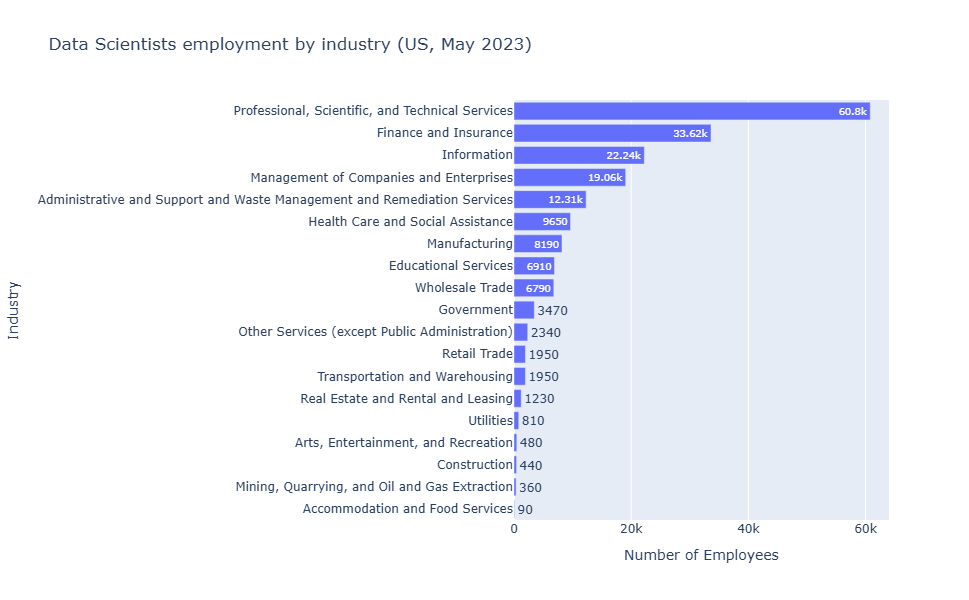

In [148]:
# Sort the industries by number of employees
industry_emp = industry.sort_values(by="TOT_EMP")
# Keep only the Data Scientists rows
data_scientists = industry_emp.loc[(industry_emp['OCC_TITLE'] == "Data Scientists")].copy()
#The industry name was taking too much space so I shortned
data_scientists["NAICS_TITLE"] = data_scientists["NAICS_TITLE"].replace({"Federal, State, and Local Government, excluding State and Local Government Schools and Hospitals and the U.S. Postal Service (OEWS Designation)": "Government"})
# Horizontal bar chart: employees per industry
fig = px.bar(
    data_scientists,
    x="TOT_EMP",
    y="NAICS_TITLE",
    orientation="h",
    title="Data Scientists employment by industry (US, May 2023)",
    labels={"TOT_EMP": "Number of Employees", "NAICS_TITLE":"Industry"},
    height=600,
    text_auto=True
)
fig.show()

- **Calculations:**

In [149]:
# Total Data Scientists in all industries
total = data_scientists["TOT_EMP"].sum()
# Industry with the most Data Scientists
top_one = data_scientists["TOT_EMP"].max()
# Sum of the three biggest industries
top_three = data_scientists["TOT_EMP"].nlargest(3).sum()
# Show as %
print("Top industry share:", round(top_one / total * 100, 1), "%")
print("Top three industry share:", round(top_three / total * 100, 1), "%")

Top industry share: 31.6 %
Top three industry share: 60.5 %


- **What I learned:** Data scientists are more found in industries such as Professional, Scientific, and Technical Services (60,800) and less in Accommodation and Food Services (90). This suggests the industries whose business rely more on information of data will need more Data Scientists.

<a id="11"></a>
## Visualisation 2 - Histogram
- **Objective:** Investigate how Software Developers median pay is distributed across the 51 states
- **Visualisation type:** The histogram to show how a numeric value (median pay) is distributed across the states showing how concentrated or spread out they are.

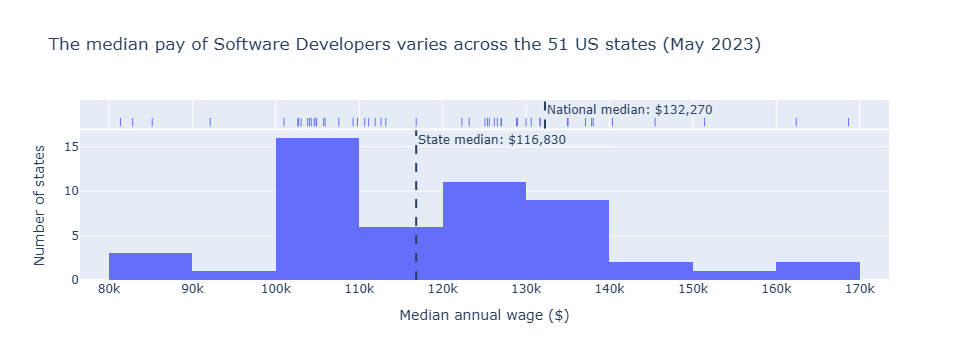

In [151]:
# Keep only the Software Developers rows for each state
software_states = state.loc[(state['OCC_TITLE'] == "Software Developers")]
# National median pay of Software Developers
national_median_software = national.loc[national['OCC_TITLE'] == "Software Developers", "A_MEDIAN"].iloc[0]
# Median of the 51 states medians
state_median_software = state.loc[state['OCC_TITLE'] == "Software Developers", "A_MEDIAN"].median()
# Histogram of the median pay with a rug plot on top
fig_hist = px.histogram(
    software_states,
    x = 'A_MEDIAN',
    nbins = 10,
    title = 'The median pay of Software Developers varies across the 51 US states (May 2023)',
    labels = {"A_MEDIAN" : "Median annual wage ($)", "count": "Number of states"},
    marginal="rug",
    hover_name="AREA_TITLE"
)
# Dashed lines for the national and state medians
fig_hist.add_vline(x=national_median_software, line_dash="dash", row=2, col=1,annotation_text=f"National median: ${national_median_software:,.0f}")
fig_hist.add_vline(x=state_median_software, line_dash="dash", row=1, col=1, annotation_text=f"State median: ${state_median_software:,.0f}")
# Rename the y axis
fig_hist.update_layout(yaxis_title="Number of states")
fig_hist.show()

- **What I learned:** The median pay across the 51 states in the US for Software Developers varies from `$81,380` in West Virginia being the lowest to `$168,660` in California being the highest paying state. The most common range between states is between `$100,000` and `$110,000` with 16 states. This suggests that the Software Developers can earn more or less depending on which state they work on. 42 of the 51 states fall between `$100,000` and `$140,000`. The median across states is `$116,830`

- **Understanding Data:**

In [152]:
# States ordered from lowest to highest median pay (also seen in rug)
software_states.sort_values(by="A_MEDIAN")[["AREA_TITLE", "A_MEDIAN"]]

,AREA_TITLE,A_MEDIAN
181590,West Virginia,81380.0
181583,South Dakota,82850.0
181566,Mississippi,85190.0
181545,Arkansas,92140.0
181576,North Dakota,100980.0
181591,Wisconsin,102660.0
181554,Idaho,102700.0
181542,Alabama,102730.0
181559,Kentucky,103030.0
181564,Michigan,103830.0


<a id="12"></a>
## Visualisation 3 - Scatter Plot
- **Objective:** Investigate whether states with more developers pay them more.
- **Visualisation type:** Relationship between two numeric variables (Number of Software Developers and their median pay) in each state

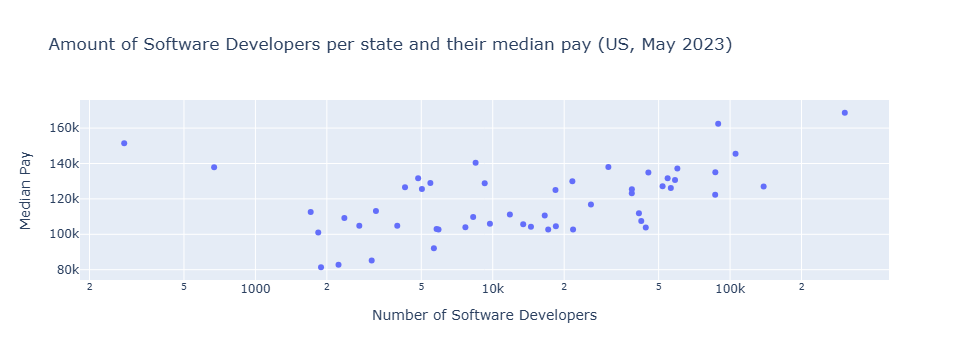

In [156]:
# Scatter plot: number of developers vs median pay per state (log scale on x, so chart is with better visibility, California pulls the chart)
fig_scatter = px.scatter(
    software_states,
    x = "TOT_EMP",
    y = "A_MEDIAN",
    log_x = True,
    hover_name = "AREA_TITLE",
    title = "Amount of Software Developers per state and their median pay (US, May 2023)",
    labels = {"TOT_EMP" : "Number of Software Developers ", "A_MEDIAN": "Median Pay "}
)
fig_scatter.show()

- **Calculations:**

In [157]:
# Correlation between number of Developers and median pay
print("Correlation of employees to median pay is", round(software_states["TOT_EMP"].corr(software_states["A_MEDIAN"]), 2))

Correlation of employees to median pay is 0.58


In [158]:
# States that pay more than national median
high_pay_states = software_states.loc[software_states["A_MEDIAN"] > national_median_software]
print(len(high_pay_states), "states pay above the national median")
# Developers in those states
high_pay_devs = high_pay_states["TOT_EMP"].sum()
# Developers in all states
all_devs = software_states["TOT_EMP"].sum()
# % of Developers working in the high paying states
print(round(high_pay_devs / all_devs *100, 1), "% of developer work in the 10 states that pay above the national median")

10 states pay above the national median
44.1 % of developer work in the 10 states that pay above the national median


- **What I learned:** Most low-employment states are low-paying, Alaska and Wyoming being the exceptions, The four lowest dots after those, around `$80k-$85k`, are all on the left, with only a few thousand developers each. Most high-employment states are high-paying. The dots on the right are mostly above `$120k`. The highest-paying state, California, is also the one with most developers. The correlation of 0.58 is a moderate positive relationship, it is not a rule, but a tendency. This chart explains why the national median (`$132,270`) is above the state median (`$116,830`) in visualisation 2. States like California, New York, and Washington and seven other states pay above the national median. Those employ 44% of the total Software Developers pulling the median up comparing to the state median.

<a id="13"></a>
## Visualisation 4 - Pie Chart
- **Objective:** Discover the amount of employees per field (5 fields for better visualisation)
- **Visualisation type:** Categories (field occupations) as parts of a whole (the selected fields)

In [159]:
#The 5 occupations compared in visualisations 4 to 8
fields = ["Software Developers",
"Software Quality Assurance Analysts and Testers",
"Data Scientists",
"Computer Programmers",
"Computer and Information Research Scientists"]
# Keep only those 5 occupations from national table
national_fields = national[national["OCC_TITLE"].isin(fields)].copy()

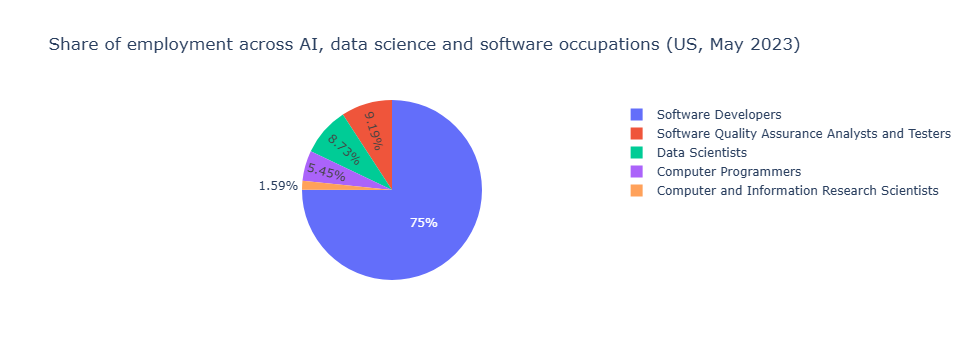

In [160]:
#Pie chart: % of employees in each occupation
fig_pie = px.pie(
    national_fields,
    names = "OCC_TITLE", 
    values = "TOT_EMP",
    title = "Share of employment across AI, data science and software occupations (US, May 2023)",
    labels = {"TOT_EMP" : "Number of employees ", "OCC_TITLE": "Field", "A_MEDIAN" : "Median pay"},
    hover_data = ["A_MEDIAN"]
)
fig_pie.show()

- **Calculations:**

In [161]:
#Total employees in the 5 occupations
total_share = national_fields["TOT_EMP"].sum()
print(f"Total of employees across AI, data science and software occupations: {total_share:,.0f}")
# Median pay of Computer and Information Research Scientists
ai_median = national_fields.loc[national_fields["OCC_TITLE"] == "Computer and Information Research Scientists", "A_MEDIAN"].iloc[0]
# Difference in dollars to the other occupations
national_fields["difference"] = ai_median - national_fields["A_MEDIAN"]
# How many % more the research scientists earn
national_fields["percent_more"] = ((ai_median / national_fields["A_MEDIAN"] - 1) * 100).round(1)
#Show the comparison table
national_fields[["OCC_TITLE", "A_MEDIAN", "difference", "percent_more"]]

Total of employees across AI, data science and software occupations: 2,208,210


,OCC_TITLE,A_MEDIAN,difference,percent_more
138,Computer and Information Research Scientists,145080.0,0.0,0.0
148,Computer Programmers,99700.0,45380.0,45.5
149,Software Developers,132270.0,12810.0,9.7
150,Software Quality Assurance Analysts and Testers,101800.0,43280.0,42.5
165,Data Scientists,108020.0,37060.0,34.3


- **What I learned:** I learned that `75%` of the employees are found in the Software Developers field, while Software Quality Assurance Analysts and Testers and Data Scientists are both approximatelly `9%` and Computer Programmers `5.5%`. The smallest group of employees is in Computer and Information Research Scientists with only `1.6%`. It reports that three of the five occupations are sofware roles, and together they make up about 90% of these jobs and that AI is a very small field with only `35,210` employees out of `2,208,210`, however it is the one with the highest paying median with `$145,080`, which suggests a hightly specialised field earning `10%` more than Software Developers and around `35-45%` more than the other three fields.

<a id="14"></a>
## Visualisation 5 - Heatmap
- **Objective:** Find out which industries employ each of the five occupations
- **Visualisation type:** Heatmap shows a number for every combination of two categories (industry x occupation) as colour, so patters stand out.

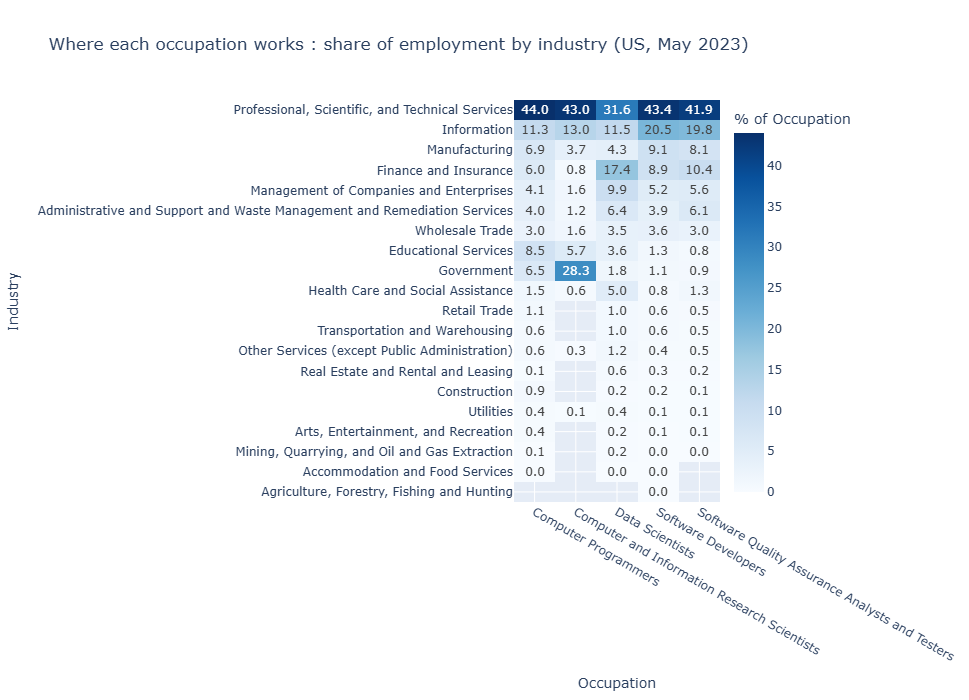

In [95]:
# Keep the 5 occupations in the industry table
industry_fields = industry[industry["OCC_TITLE"].isin(fields)].copy()
# Shorten the long goverment industry
industry_fields["NAICS_TITLE"] = industry_fields["NAICS_TITLE"].replace({"Federal, State, and Local Government, excluding State and Local Government Schools and Hospitals and the U.S. Postal Service (OEWS Designation)": "Government"})
# Table with industries as rows and occupations as columns
industry_grid = industry_fields.pivot(index="NAICS_TITLE",
                             columns="OCC_TITLE", 
                             values="TOT_EMP")
# Turn the numbers into % of each occupation
industry_grid_pct = industry_grid / industry_grid.sum() * 100
# Order by Software Developers
industry_grid_pct = industry_grid_pct.sort_values(by="Software Developers", ascending=False)
#Heatmap of the %
fig_heat = px.imshow(
    industry_grid_pct,
    text_auto=".1f",
    aspect="auto",
    color_continuous_scale="Blues",
    labels=dict(x = "Occupation", y = "Industry", color = "% of Occupation"),
    title = "Where each occupation works : share of employment by industry (US, May 2023)",
    height = 700
)
fig_heat.show()

- **What I learned:** I learned that all five occupations are mostly in the Professional, Scientific, and Technical industry as already discovered in visualisation 1, however now it shows how much each one is present in each field with all between `30-44%`, with Data Scientist with less from the five for being spread out with `17.4%` in Finance and Insurance. AI is also `28%` used by Goverment; Software Developers and Analysts and Testers are approximately `20%` in Information. This heatmap shows that those five fields lean on different in each industry.

<a id="15"></a>
## Challenge
- **Objective of the challenge:** Load files from the other years in https://www.bls.gov/oes/tables.htm to see how employment and pay in **AI, Data Science, and Software** changed over time.
- **Years:** 2021, 2022, 2023 (main dataset), 2024 and 2025.
- Same steps were followed to: 
1. Read the file
2. Copy and clean
3. Tables

<a id="16"></a>
### Loading dataset for years

<a id="17"></a>
#### 2021

In [162]:
# 1. Read the file
dataset_2021 =  pd.read_excel("all_data_M_2021.xlsx")

# 2. Copy and clean
clean_2021 = dataset_2021.copy()

for col in ["A_MEDIAN", "TOT_EMP", "A_MEAN"]:
    clean_2021[col] = clean_2021[col].replace("#", 239200)
    clean_2021[col] = pd.to_numeric(clean_2021[col], errors="coerce")

# 3. National table
national_2021=clean_2021.loc[(clean_2021['AREA_TYPE'] == 1) & (clean_2021["I_GROUP"] == "cross-industry") & (clean_2021["O_GROUP"] == "detailed") & (clean_2021["OCC_CODE"].str.startswith("15-"))]

national_fields_2021 = national_2021[national_2021["OCC_TITLE"].isin(fields)].copy()
national_fields_2021["YEAR"] = 2021

In [163]:
# Check the 2021 rows
national_fields_2021[["OCC_TITLE", "TOT_EMP", "A_MEDIAN"]]

,OCC_TITLE,TOT_EMP,A_MEDIAN
138,Computer and Information Research Scientists,30840.0,131490.0
148,Computer Programmers,152610.0,93000.0
149,Software Developers,1364180.0,120730.0
150,Software Quality Assurance Analysts and Testers,190120.0,98220.0
165,Data Scientists,105980.0,100910.0


<a id="18"></a>
#### 2022

In [164]:
# 1. Read the file
dataset_2022 =  pd.read_excel("all_data_M_2022.xlsx")

# 2. Copy and clean
clean_2022 = dataset_2022.copy()

for col in ["A_MEDIAN", "TOT_EMP", "A_MEAN"]:
    clean_2022[col] = clean_2022[col].replace("#", 239200)
    clean_2022[col] = pd.to_numeric(clean_2022[col], errors="coerce")

# 3. National table
national_2022=clean_2022.loc[(clean_2022['AREA_TYPE'] == 1) & (clean_2022["I_GROUP"] == "cross-industry") & (clean_2022["O_GROUP"] == "detailed") & (clean_2022["OCC_CODE"].str.startswith("15-"))]

national_fields_2022 = national_2022[national_2022["OCC_TITLE"].isin(fields)].copy()
national_fields_2022["YEAR"] = 2022

In [165]:
# Check the 2022 rows
national_fields_2022[["OCC_TITLE", "TOT_EMP", "A_MEDIAN"]]

,OCC_TITLE,TOT_EMP,A_MEDIAN
138,Computer and Information Research Scientists,33780.0,136620.0
148,Computer Programmers,132740.0,97800.0
149,Software Developers,1534790.0,127260.0
150,Software Quality Assurance Analysts and Testers,196420.0,99620.0
165,Data Scientists,159630.0,103500.0


<a id="19"></a>
#### 2024

In [167]:
# 1. Read the file
dataset_2024 =  pd.read_excel("all_data_M_2024.xlsx")

# 2. Copy and clean
clean_2024 = dataset_2024.copy()

for col in ["A_MEDIAN", "TOT_EMP", "A_MEAN"]:
    clean_2024[col] = clean_2024[col].replace("#", 239200)
    clean_2024[col] = pd.to_numeric(clean_2024[col], errors="coerce")

# 3. National table
national_2024=clean_2024.loc[(clean_2024['AREA_TYPE'] == 1) & (clean_2024["I_GROUP"] == "cross-industry") & (clean_2024["O_GROUP"] == "detailed") & (clean_2024["OCC_CODE"].str.startswith("15-"))]

national_fields_2024 = national_2024[national_2024["OCC_TITLE"].isin(fields)].copy()
national_fields_2024["YEAR"] = 2024

In [101]:
# Check the 2024 rows
national_fields_2024[["OCC_TITLE", "TOT_EMP", "A_MEDIAN"]]

,OCC_TITLE,TOT_EMP,A_MEDIAN
138,Computer and Information Research Scientists,38480.0,140910.0
148,Computer Programmers,109870.0,98670.0
149,Software Developers,1654440.0,133080.0
150,Software Quality Assurance Analysts and Testers,199800.0,102610.0
165,Data Scientists,233440.0,112590.0


<a id="20"></a>
#### 2025

In [169]:
# 1. Read the file
dataset_2025 =  pd.read_excel("all_data_M_2025.xlsx")

# 2. Copy and clean
clean_2025 = dataset_2025.copy()

for col in ["A_MEDIAN", "TOT_EMP", "A_MEAN"]:
    clean_2025[col] = clean_2025[col].replace("#", 239200)
    clean_2025[col] = pd.to_numeric(clean_2025[col], errors="coerce")

# 3. National table
national_2025=clean_2025.loc[(clean_2025['AREA_TYPE'] == 1) & (clean_2025["I_GROUP"] == "cross-industry") & (clean_2025["O_GROUP"] == "detailed") & (clean_2025["OCC_CODE"].str.startswith("15-"))]

national_fields_2025 = national_2025[national_2025["OCC_TITLE"].isin(fields)].copy()
national_fields_2025["YEAR"] = 2025

In [170]:
# Check the 2025 rows
national_fields_2025[["OCC_TITLE", "TOT_EMP", "A_MEDIAN"]]

,OCC_TITLE,TOT_EMP,A_MEDIAN
136,Computer and Information Research Scientists,37200.0,140300.0
146,Computer Programmers,92230.0,100390.0
147,Software Developers,1687890.0,135980.0
148,Software Quality Assurance Analysts and Testers,186740.0,104300.0
163,Data Scientists,262440.0,120230.0


<a id="21"></a>
### Combining tables

The 5 years are stacked into one table (trend) with pd.concat

In [171]:
#Same 5 occupations with the year column
national_fields_2023 = national[national["OCC_TITLE"].isin(fields)].copy()
national_fields_2023["YEAR"] = 2023
#Stack the 5 years in one table
trend = pd.concat([national_fields_2021, national_fields_2022, national_fields_2023, national_fields_2024, national_fields_2025])
trend.shape

(25, 33)

<a id="22"></a>
## Visualisation 6 - Line Chart
- **Objective:** Find out the difference of AI, Data Science and Software employment from 2021 to 2025
- **Visualisation type:** The line chart allows to see the growth or fall (employment) through a distance (year)

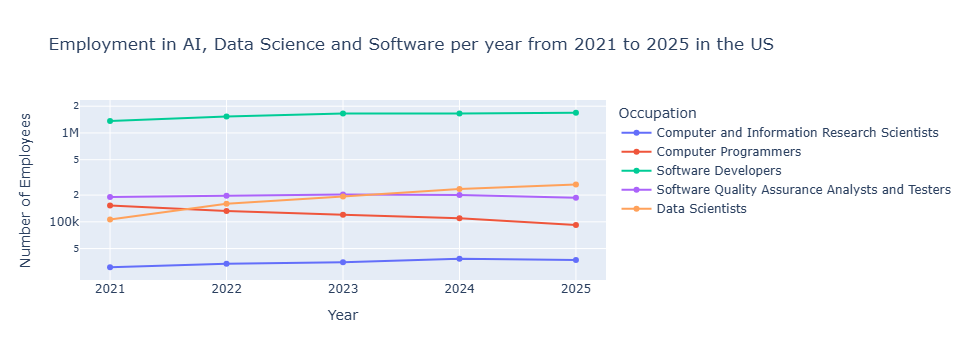

In [172]:
# Line chart: employees per year for each occupation (Log scale on y)
fig_line = px.line(
    trend,
    x = "YEAR",
    y = "TOT_EMP",
    color = "OCC_TITLE",
    markers = True,
    log_y = True,
    title = "Employment in AI, Data Science and Software per year from 2021 to 2025 in the US",
    labels = {"TOT_EMP": "Number of Employees", "YEAR":"Year", "OCC_TITLE": "Occupation"}
)
fig_line.show()

- **Calculations:**

In [175]:
#Table with occupations as rows and years as columns
trend_grid = trend.pivot(index = "OCC_TITLE", columns = "YEAR", values = "TOT_EMP")
#% change from 2021 to 2025
trend_grid["change_%"] = ((trend_grid[2025] / trend_grid[2021] - 1) * 100).round(1)
trend_grid

YEAR,2021,2022,2023,2024,2025,change_%
OCC_TITLE,,,,,,
Computer Programmers,152610.0,132740.0,120370.0,109870.0,92230.0,-39.6
Computer and Information Research Scientists,30840.0,33780.0,35210.0,38480.0,37200.0,20.6
Data Scientists,105980.0,159630.0,192710.0,233440.0,262440.0,147.6
Software Developers,1364180.0,1534790.0,1656880.0,1654440.0,1687890.0,23.7
Software Quality Assurance Analysts and Testers,190120.0,196420.0,203040.0,199800.0,186740.0,-1.8


In [176]:
#Total employees in 2021 and 2025
total_2021 = trend_grid[2021].sum()
total_2025 = trend_grid[2025].sum()
#% change of the total
total_change = (total_2025 / total_2021 - 1) * 100
print(f"Total 2021: {total_2021:,.0f}")
print(f"Total 2025: {total_2025:,.0f}")
print(f"Total Change: {total_change:,.1f}%")

Total 2021: 1,843,730
Total 2025: 2,266,500
Total Change: 22.9%


- **What I learned:** This graph shows that Data Scientists climb `147.6%` from 2021 to 2025. Computer and Information Research Scientists and Software Developers also climb, but not as much with around `21-24%`, Software Developers grows until 2023 and then level off. There is a decline on Computer Programmers of `39.6%`. Software Quality Assurance Analysts and Testers is the one that changed the least, but still declined almost `2%` compared to 2021. Data Scientists employment passed both Software Quality Assurance Analysts and Testers and Computer programs during this time. The field most connected to AI and data is the one growing fastest. While some areas decreased and others increased, there was a total of 22.9% increase of employees from 2021 to 2025.

<a id="23"></a>
## Visualisation 7 - Line Chart
- **Objective:** Find out the difference of AI, Data Science and Software median pay from 2021 to 2025
- **Visualisation type:** The line chart allows to see the growth or fall (median pay) through a distance (year)

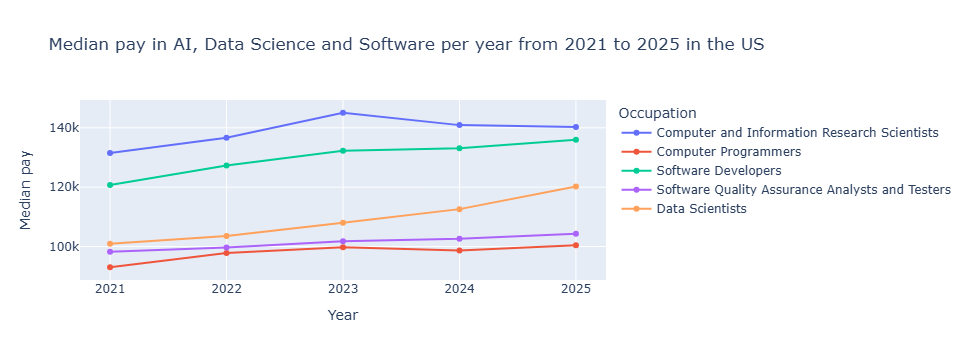

In [177]:
# Line chart: median pay per year for each occupation
fig_line_pay = px.line(
    trend,
    x = "YEAR",
    y = "A_MEDIAN",
    color = "OCC_TITLE",
    markers = True,
    title = "Median pay in AI, Data Science and Software per year from 2021 to 2025 in the US",
    labels = {"A_MEDIAN": "Median pay", "YEAR":"Year", "OCC_TITLE": "Occupation"}
)
fig_line_pay.show()

In [178]:
#Table with occupations as rows and years as columns (median pay)
trend_grid_pay = trend.pivot(index = "OCC_TITLE", columns = "YEAR", values = "A_MEDIAN")
#% change fromn 2021 to 2025
trend_grid_pay["change_%"] = ((trend_grid_pay[2025] / trend_grid_pay[2021] - 1) * 100).round(1)
trend_grid_pay
#Avarage of the 5 medians in 2021 and 2025
median_pay_2021 = trend_grid_pay[2021].mean()
median_pay_2025 = trend_grid_pay[2025].mean()
#% change of the avg
median_pay_change = (median_pay_2025 / median_pay_2021 - 1) * 100
print(f"Average pay of 2021: {median_pay_2021:,.0f}")
print(f"Average pay of 2025: {median_pay_2025:,.0f}")
print(f"Total Change: {median_pay_change:.1f}%")
#Highest median pay of the research scientists
ai_peak = trend_grid_pay.loc["Computer and Information Research Scientists", [2021, 2022, 2023, 2024, 2025]].max()
print(f"Research Scientists peak median pay: {ai_peak:,.0f}")
#Ocuppations ordered by biggest pay change
trend_grid_pay.sort_values(by="change_%", ascending=False)

Average pay of 2021: 108,870
Average pay of 2025: 120,240
Total Change: 10.4%
Research Scientists peak median pay: 145,080


YEAR,2021,2022,2023,2024,2025,change_%
OCC_TITLE,,,,,,
Data Scientists,100910.0,103500.0,108020.0,112590.0,120230.0,19.1
Software Developers,120730.0,127260.0,132270.0,133080.0,135980.0,12.6
Computer Programmers,93000.0,97800.0,99700.0,98670.0,100390.0,7.9
Computer and Information Research Scientists,131490.0,136620.0,145080.0,140910.0,140300.0,6.7
Software Quality Assurance Analysts and Testers,98220.0,99620.0,101800.0,102610.0,104300.0,6.2


- **What I learned:** For all five of the occupations the median pay rose, Dat Scientists being with the most change with `19.1%` and QA Testers with `6.2%`. Their medians avarage changed from `$108,870` to `$120,240`(`10.4%`). The shape of the line shows that AI Research Scientists pay peaked in 2023 (`$145,080`) and fell back, but still remain the best paid. Data Scientists gets close to Software Developers in 2025 making the steepest line.
Comapring with the previous visualisation The higher pay and more jobs available in both Data Scientists suggests demand is outpacing supply.

<a id="24"></a>
## Visualisation 8 - Grouped Bar Chart
- **Objective:** Compare each occupation employment and pay changed over the same period
- **Visualisation type:** The grouped bar helps to see two measures (pay and employment) for different categories (occupations), side by side

In [114]:
#Employment change and pay side by side
change_table = pd.DataFrame({
    "Employment change (%)": trend_grid["change_%"],
    "Pay change (%)": trend_grid_pay["change_%"],
})
# Turn the occupation names back into a column
change_table = change_table.reset_index()
change_table

,OCC_TITLE,Employment change (%),Pay change (%)
0,Computer Programmers,-39.6,7.9
1,Computer and Information Research Scientists,20.6,6.7
2,Data Scientists,147.6,19.1
3,Software Developers,23.7,12.6
4,Software Quality Assurance Analysts and Testers,-1.8,6.2


In [179]:
# Change to long format
change_long = change_table.melt(id_vars="OCC_TITLE", var_name="Measure", value_name="Change (%)")
change_long

,OCC_TITLE,Measure,Change (%)
0,Computer Programmers,Employment change (%),-39.6
1,Computer and Information Research Scientists,Employment change (%),20.6
2,Data Scientists,Employment change (%),147.6
3,Software Developers,Employment change (%),23.7
4,Software Quality Assurance Analysts and Testers,Employment change (%),-1.8
5,Computer Programmers,Pay change (%),7.9
6,Computer and Information Research Scientists,Pay change (%),6.7
7,Data Scientists,Pay change (%),19.1
8,Software Developers,Pay change (%),12.6
9,Software Quality Assurance Analysts and Testers,Pay change (%),6.2


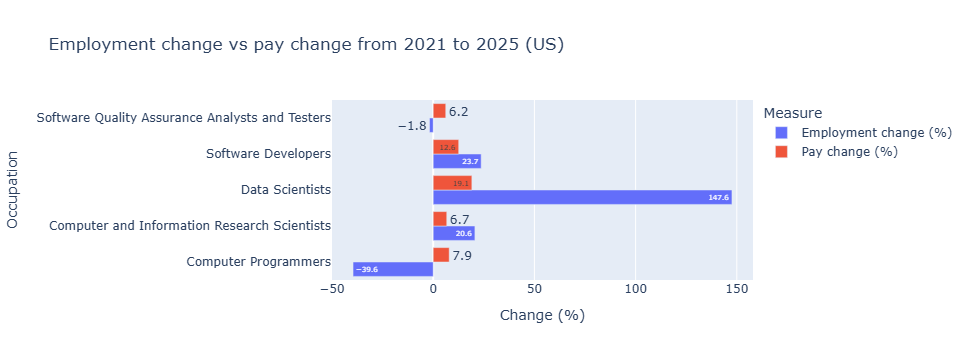

In [180]:
#Grouped horizontal bar chart: employment change vs pay change
fig_change = px.bar(
    change_long,
    x="Change (%)",
    y="OCC_TITLE",
    color="Measure",
    barmode="group",
    orientation="h",
    text_auto=True,
    title="Employment change vs pay change from 2021 to 2025 (US)",
    labels={"OCC_TITLE": "Occupation"}
)
fig_change.show()

- **What I learned:** As seen in visualisation 6 and 7, this one shows both from 2021 to 2025. Data Scientists are the only the grew both in pay and jobs. Research Scientists and Software Developers grew moderately, both had almost the same difference in employement increase, but Sofware Developers still got almost twice much than Research Scientists. For Programmers and QA Testers there were losts of job while the pay increased, that could mean there are more specialised jobs.

<a id="25"></a>
# References:
- Ahmed, T. (n.d.) *Data Visualisation and Communication: class notebooks* [Jupyter notebooks]. Unpublished lecture materials. Notebooks used:
    - Pandas: DataFrame reference (`loc`, `concat`, `merge`), diamonds CSV and diamonds EDA (filtering, `groupby`, sorting)
    - Matplotlib: intro line plots (filtering a dataset and plotting by year)
    - Plotly interactive: iris (`px.bar`, `px.histogram`, `px.scatter`, `px.pie`)
    - CA-1 type tutorial, Titanic (structure of objective, visualisation type and learning for each chart)
    - Data cleaning: missing data (`replace`, missing values)
- Ekiz, A. (2022) *Creating Table of Contents in Jupyter Notebook*. Medium, 5 July. Available at: https://medium.com/@ahmetekiz/creating-table-of-contents-in-jupyter-notebook-52a7c696817f (Accessed: 6 November 2026).
- Pandas (n.d.). Pandas.DataFrame.Pivot — Pandas 1.3.5 documentation. [online] pandas.pydata.org. Available at: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pivot.html [Accessed 13 Oct. 2026].
- Pandas (n.d.). pandas.Series.nlargest. [online] Pandas Documentation. Available at: https://pandas.pydata.org/docs/reference/api/pandas.Series.nlargest.html [Accessed 13 Oct. 2026].
- Pandas (n.d.). pandas.Series.str.startswith. [online] Pandas documentation. Available at: https://pandas.pydata.org/docs/reference/api/pandas.Series.str.startswith.html# [Accessed 13 Oct. 2026].
- Pandas (n.d.). Pandas.To_numeric — Pandas 1.4.2 documentation. [online] pandas.pydata.org. Available at: https://pandas.pydata.org/docs/reference/api/pandas.to_numeric.html [Accessed 13 Oct. 2026].
- Plotly (2024). Imshow. [online] Plotly.com. Available at: https://plotly.com/python/imshow/ [Accessed 4 Nov. 2026].
- Plotly (n.d.). Bar charts. [online] plotly.com. Available at: https://plotly.com/python/bar-charts/ [Accessed 13 Oct. 2026].
- Plotly (n.d.). Log Plots in Python. Plotly documentation.
- Plotly (n.d.). Marginal distribution plots in Python. [online] Plotly. Available at: https://plotly.com/python/marginal-plots/ [Accessed 4 Nov. 2026].
- Plotly (n.d.). Marginal distribution plots in Python. [online] Plotly. Available at: https://plotly.com/python/marginal-plots/ [Accessed 4 Nov. 2026].
- Satopay, H. (2019). The ultimate markdown guide (for jupyter notebook) - analytics vidhya - medium. [online] Medium. Available at: https://medium.com/analytics-vidhya/the-ultimate-markdown-guide-for-jupyter-notebook-d5e5abf728fd [Accessed 13 Oct. 2026].
- U.S. Bureau of Labor Statistics (2024) *Occupational Employment and Wage Statistics, May 2023* [all data]. Available at: https://www.bls.gov/oes/tables.htm
- U.S. Bureau of Labor Statistics, *Occupational Employment and Wage Statistics* tables for May 2021, May 2022, May 2024 and May 2025 [all data]. Available at: https://www.bls.gov/oes/tables.htm

- I didn't use AI for any of the writing or to do the assignment. I only used AI to study the profe